# Autonomous Delivery Drones — Route Planning with Q-Learning

A logistics company wants its drones to fly packages from any pickup point in a delivery zone to the **delivery truck** by the shortest possible route, without ever entering a **no-fly zone**.

This notebook trains a **tabular Q-learning** agent to solve that problem from scratch. The agent gets no map and no routing algorithm, only rewards. It then checks the learned routes against the true shortest paths found by breadth-first search.

| | |
|---|---|
| **Environment** | 10 × 10 grid: 1 delivery truck (goal), 54 flight-corridor cells, 45 no-fly cells |
| **Actions** | up, right, down, left |
| **Rewards** | +100 for reaching the truck, −1 per corridor step, −100 for entering a no-fly zone (episode ends) |
| **Algorithm** | Q-learning with an ε-greedy policy |
| **Result** | the learned policy reaches the truck from **every** corridor cell using a **provably shortest** route |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
from matplotlib.colors import ListedColormap

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. The environment

Every cell of the grid is a **state**. Each state has a reward: corridor cells cost −1 (so shorter routes score higher), no-fly zones cost −100 and end the episode (a crash), and the truck at row 0, column 5 is worth +100.

In [2]:
ROWS, COLS = 10, 10
GOAL = (0, 5)
ACTIONS = ["up", "right", "down", "left"]
MOVES = [(-1, 0), (0, 1), (1, 0), (0, -1)]

rewards = np.full((ROWS, COLS), -100.0)   # default: no-fly zone
rewards[GOAL] = 100.0                      # delivery truck

# flight corridors (cells the drone may fly through), by row
corridors = {
    1: list(range(1, 10)),
    2: [1, 7, 9],
    3: list(range(1, 8)) + [9],
    4: [3, 7],
    5: list(range(10)),
    6: [5],
    7: list(range(1, 10)),
    8: [3, 7],
    9: list(range(10)),
}
for r, cols in corridors.items():
    rewards[r, cols] = -1.0

corridor_cells = [(r, c) for r in range(ROWS) for c in range(COLS) if rewards[r, c] == -1.0]
print(f"corridor cells: {len(corridor_cells)}   no-fly cells: {(rewards == -100).sum()}   goal: {GOAL}")

corridor cells: 54   no-fly cells: 45   goal: (0, 5)


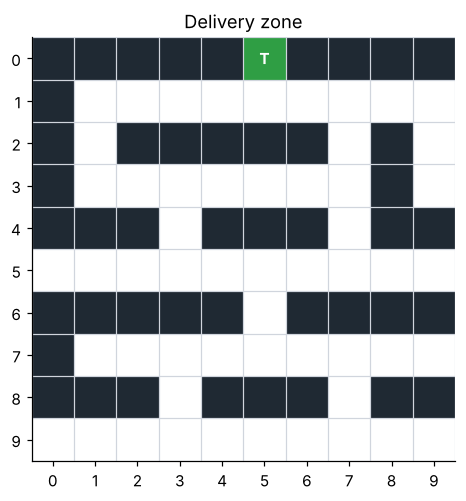

In [3]:
def draw_map(ax, title=None):
    """Black = no-fly zone, white = corridor, green = delivery truck."""
    grid = np.where(rewards == -100, 0, np.where(rewards == 100, 2, 1))
    ax.imshow(grid, cmap=ListedColormap(["#1f2933", "#ffffff", "#2f9e44"]), vmin=0, vmax=2)
    ax.set_xticks(range(COLS)); ax.set_yticks(range(ROWS))
    ax.set_xticks(np.arange(-.5, COLS), minor=True); ax.set_yticks(np.arange(-.5, ROWS), minor=True)
    ax.grid(which="minor", color="#d0d5dd", linewidth=0.8)
    ax.tick_params(which="minor", length=0)
    ax.text(GOAL[1], GOAL[0], "T", ha="center", va="center", color="white", fontweight="bold")
    if title:
        ax.set_title(title)

fig, ax = plt.subplots(figsize=(5, 5))
draw_map(ax, "Delivery zone")
fig._save_as = "map.png"

## 2. Agent helpers

The agent follows an **ε-greedy** policy. With probability ε it **explores** (picks a random action); otherwise it **exploits** (picks the action with the highest Q-value).

> The original version named the parameter `exploration_rate = 0.9` but used it as the probability of acting *greedily*. Here ε means what it says: ε = 0.1 explores 10% of the time, which is the same behaviour as before with an honest name.

In [4]:
def is_terminal(r, c):
    return rewards[r, c] != -1.0

def random_start():
    return corridor_cells[rng.integers(len(corridor_cells))]

def choose_action(q, r, c, epsilon):
    if rng.random() < epsilon:
        return int(rng.integers(4))          # explore
    return int(np.argmax(q[r, c]))           # exploit

def step(r, c, a):
    """Move one cell; flying off the edge of the map leaves the drone in place."""
    dr, dc = MOVES[a]
    return min(max(r + dr, 0), ROWS - 1), min(max(c + dc, 0), COLS - 1)

## 3. Training

The Q-learning update after each move from state *s* to *s′* with action *a* and reward *r*:

$$Q(s,a) \leftarrow Q(s,a) + \alpha \big[\, r + \gamma \max_{a'} Q(s',a') - Q(s,a) \,\big]$$

In [5]:
def train(episodes=1000, alpha=0.9, gamma=0.9, epsilon=0.1, eval_every=None):
    q = np.zeros((ROWS, COLS, 4))
    hist = {"steps": [], "reward": [], "success": [], "optimal_frac": []}
    for ep in range(episodes):
        r, c = random_start()
        total, n = 0.0, 0
        while not is_terminal(r, c):
            a = choose_action(q, r, c, epsilon)
            nr, nc = step(r, c, a)
            reward = rewards[nr, nc]
            td_target = reward + gamma * np.max(q[nr, nc]) * (not is_terminal(nr, nc))
            q[r, c, a] += alpha * (td_target - q[r, c, a])
            r, c = nr, nc
            total += reward; n += 1
        hist["steps"].append(n)
        hist["reward"].append(total)
        hist["success"].append((r, c) == GOAL)
        if eval_every and (ep + 1) % eval_every == 0:
            hist["optimal_frac"].append((ep + 1, evaluate(q)["optimal_rate"]))
    return q, hist

Training stops the update at terminal states (`* (not is_terminal(...))`). A crash or arrival has no future, so its value should not be bootstrapped. The original code always added γ·max Q(s′), which still converges here only because terminal Q-values stay at 0.

Before training we need a way to score a policy, so the evaluation helpers come first.

In [6]:
def greedy_route(q, start, max_steps=100):
    """Follow the learned policy from `start`. Returns the list of cells visited."""
    r, c = start
    path = [(r, c)]
    while not is_terminal(r, c) and len(path) <= max_steps:
        r, c = step(r, c, int(np.argmax(q[r, c])))
        path.append((r, c))
    return path

def bfs_distances():
    """True shortest-path length (in moves) from every corridor cell to the truck."""
    dist = {GOAL: 0}
    queue = deque([GOAL])
    while queue:
        r, c = queue.popleft()
        for dr, dc in MOVES:
            nr, nc = r + dr, c + dc
            if 0 <= nr < ROWS and 0 <= nc < COLS and rewards[nr, nc] == -1.0 and (nr, nc) not in dist:
                dist[(nr, nc)] = dist[(r, c)] + 1
                queue.append((nr, nc))
    return dist

SHORTEST = bfs_distances()

def evaluate(q):
    reached = optimal = 0
    for cell in corridor_cells:
        path = greedy_route(q, cell)
        if path[-1] == GOAL:
            reached += 1
            optimal += (len(path) - 1) == SHORTEST[cell]
    n = len(corridor_cells)
    return {"reach_rate": reached / n, "optimal_rate": optimal / n}

In [7]:
q_values, history = train(episodes=1000, alpha=0.9, gamma=0.9, epsilon=0.1, eval_every=10)
print("Training complete!")
print("Final evaluation:", evaluate(q_values))

Training complete!
Final evaluation: {'reach_rate': 1.0, 'optimal_rate': 1.0}


## 4. Learning curves

All 54 start cells follow a shortest route from episode 430 onwards


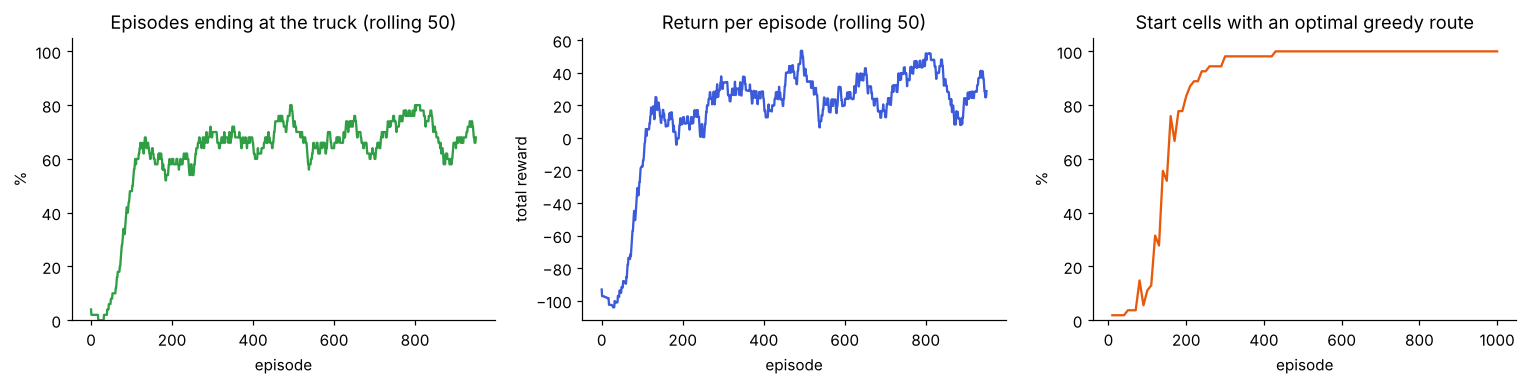

In [8]:
def rolling(x, w=50):
    x = np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(w) / w, mode="valid")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].plot(rolling(history["success"]) * 100, color="#2f9e44")
axes[0].set(title="Episodes ending at the truck (rolling 50)", xlabel="episode", ylabel="%", ylim=(0, 105))
axes[1].plot(rolling(history["reward"]), color="#3b5bdb")
axes[1].set(title="Return per episode (rolling 50)", xlabel="episode", ylabel="total reward")
eps, frac = zip(*history["optimal_frac"])
axes[2].plot(eps, np.array(frac) * 100, color="#e8590c")
axes[2].set(title="Start cells with an optimal greedy route", xlabel="episode", ylabel="%", ylim=(0, 105))
fig.tight_layout()
fig._save_as = "learning_curves.png"

first_perfect = next((e for e, f in history["optimal_frac"] if f == 1.0), None)
print(f"All {len(corridor_cells)} start cells follow a shortest route from episode {first_perfect} onwards"
      if first_perfect else "Policy not yet optimal everywhere")

Early on, almost every episode ends in a crash and returns sit near −100. Within about 150 episodes, around 70% of *training* episodes reach the truck. The rest crash because of the 10% random exploratory moves: on an 18-move route there is a good chance that at least one random move hits a no-fly zone.

The right-hand panel is the real measure of learning. It follows the **greedy** policy, with no exploration, from every start cell. That reaches 100% optimal routes well before training ends.

## 5. Learned routes

Same start points as the original assignment, plus a reversed route showing the trip from the truck back out to a pickup point.

In [9]:
for start in [(3, 9), (5, 0), (9, 5)]:
    route = greedy_route(q_values, start)
    print(f"from {start}: {len(route) - 1} moves (shortest possible: {SHORTEST[start]})")
    print("   ", [list(p) for p in route])

outbound = greedy_route(q_values, (5, 2))[::-1]
print("\ntruck -> (5, 2):", [list(p) for p in outbound])

from (3, 9): 7 moves (shortest possible: 7)
    [[3, 9], [2, 9], [1, 9], [1, 8], [1, 7], [1, 6], [1, 5], [0, 5]]
from (5, 0): 14 moves (shortest possible: 14)
    [[5, 0], [5, 1], [5, 2], [5, 3], [5, 4], [5, 5], [5, 6], [5, 7], [4, 7], [3, 7], [2, 7], [1, 7], [1, 6], [1, 5], [0, 5]]
from (9, 5): 17 moves (shortest possible: 17)
    [[9, 5], [9, 6], [9, 7], [8, 7], [7, 7], [7, 6], [7, 5], [6, 5], [5, 5], [5, 6], [5, 7], [4, 7], [3, 7], [2, 7], [1, 7], [1, 6], [1, 5], [0, 5]]

truck -> (5, 2): [[0, 5], [1, 5], [1, 6], [1, 7], [2, 7], [3, 7], [4, 7], [5, 7], [5, 6], [5, 5], [5, 4], [5, 3], [5, 2]]


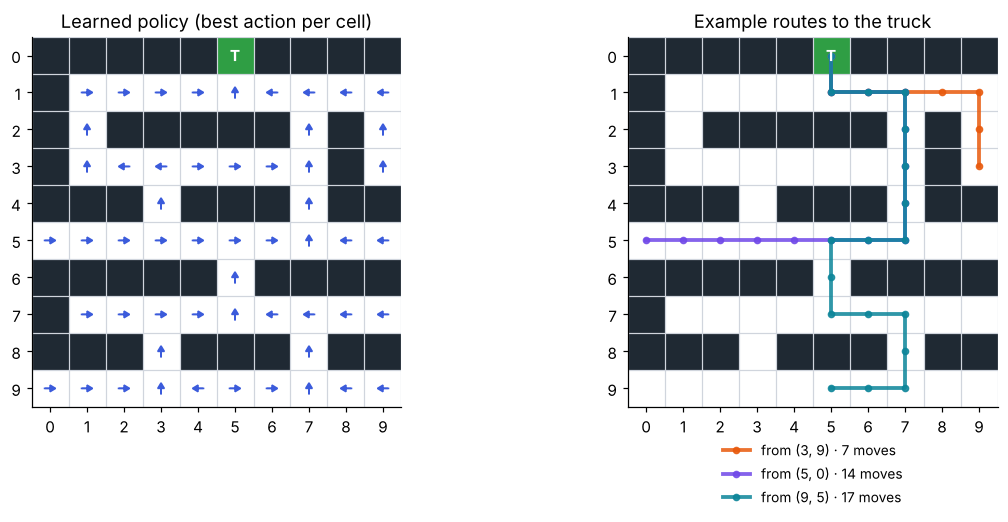

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

# (a) policy: best action in every corridor cell
draw_map(axes[0], "Learned policy (best action per cell)")
arrows = {0: (0, -0.3), 1: (0.3, 0), 2: (0, 0.3), 3: (-0.3, 0)}
for r, c in corridor_cells:
    dx, dy = arrows[int(np.argmax(q_values[r, c]))]
    axes[0].arrow(c - dx / 2, r - dy / 2, dx, dy, head_width=0.18, head_length=0.15,
                  length_includes_head=True, color="#3b5bdb")

# (b) three example routes
draw_map(axes[1], "Example routes to the truck")
for start, color in zip([(3, 9), (5, 0), (9, 5)], ["#e8590c", "#7048e8", "#0c8599"]):
    route = np.array(greedy_route(q_values, start))
    axes[1].plot(route[:, 1], route[:, 0], "-o", color=color, ms=4, lw=2.5, alpha=.85,
                 label=f"from {start} · {len(route) - 1} moves")
axes[1].legend(loc="lower center", bbox_to_anchor=(0.5, -0.30), ncol=1, frameon=False, fontsize=9)
fig.tight_layout()
fig._save_as = "policy_and_routes.png"

## 6. Is the learned policy actually optimal?

Breadth-first search gives the true shortest distance from every corridor cell to the truck. A policy is **optimal** for a start cell if its greedy route reaches the truck in exactly that many moves.

In [11]:
result = evaluate(q_values)
print(f"reaches the truck from    {result['reach_rate']:.0%} of start cells")
print(f"uses a shortest route from {result['optimal_rate']:.0%} of start cells")
print(f"longest shortest-route in this map: {max(SHORTEST.values())} moves")

reaches the truck from    100% of start cells
uses a shortest route from 100% of start cells
longest shortest-route in this map: 18 moves


## 7. Hyperparameter study

How quickly does the agent become fully optimal? For each setting I train 5 seeds and record the first episode (checked every 10) at which **every** start cell follows a shortest route.

In [12]:
def episodes_to_optimal(alpha, epsilon, seeds=5, max_episodes=3000):
    global rng
    results = []
    for s in range(seeds):
        rng = np.random.default_rng(1000 + s)
        _, h = train(episodes=max_episodes, alpha=alpha, gamma=0.9, epsilon=epsilon, eval_every=10)
        results.append(next((e for e, f in h["optimal_frac"] if f == 1.0), np.nan))
    return np.array(results, dtype=float)

alphas, epsilons = [0.1, 0.5, 0.9], [0.05, 0.1, 0.3]
table = np.zeros((len(alphas), len(epsilons)))
print("median episodes until every route is optimal (5 seeds)\n")
print("alpha \\ epsilon " + "".join(f"{e:>10}" for e in epsilons))
for i, a in enumerate(alphas):
    for j, e in enumerate(epsilons):
        table[i, j] = np.nanmedian(episodes_to_optimal(a, e))
    print(f"{a:>15}" + "".join(f"{v:>10.0f}" for v in table[i]))
rng = np.random.default_rng(SEED)

median episodes until every route is optimal (5 seeds)

alpha \ epsilon       0.05       0.1       0.3
            0.1       840       820      1265
            0.5       345       345       525
            0.9       340       875       540


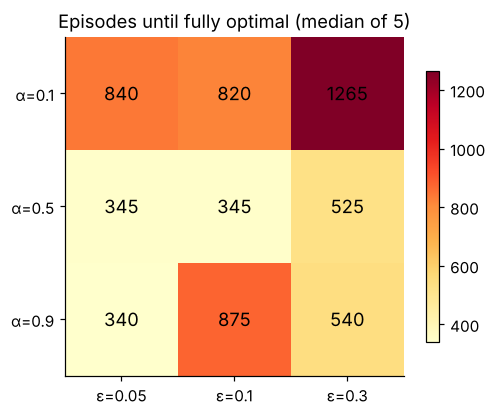

In [13]:
fig, ax = plt.subplots(figsize=(5.2, 4))
im = ax.imshow(table, cmap="YlOrRd")
ax.set_xticks(range(len(epsilons)), [f"ε={e}" for e in epsilons])
ax.set_yticks(range(len(alphas)), [f"α={a}" for a in alphas])
for i in range(len(alphas)):
    for j in range(len(epsilons)):
        ax.text(j, i, f"{table[i, j]:.0f}", ha="center", va="center", fontsize=12)
ax.set_title("Episodes until fully optimal (median of 5)")
fig.colorbar(im, ax=ax, shrink=.8)
fig._save_as = "hyperparameters.png"

## 8. Conclusions

- **The agent learns the optimal routing policy without being given a map.** After 1,000 episodes, the greedy policy reaches the truck from all 54 corridor cells, and every route matches the BFS shortest path. The longest such route is 18 moves.
- **Training success rate is not policy quality.** Only about 70% of training episodes reach the truck, because ε-greedy exploration keeps taking random moves. The greedy policy is 100% successful.
- **Learning rate matters most.** This environment is deterministic, so a high α (0.5–0.9) converges 2–3× faster than α = 0.1. There is no noise for a low learning rate to average out.
- **Too much exploration slows convergence.** With ε = 0.3, crashes end most episodes early, so the agent rarely completes long routes and learns their later steps more slowly.
- **Results vary between seeds.** Some cells in the table (for example α = 0.9, ε = 0.1) are pushed up by one or two slow seeds, which is why the table reports medians.

**Possible extensions:** multiple trucks or pickup points, wind modelled as stochastic transitions (where a lower α would start to help), battery limits, and replacing the Q-table with a small neural network (DQN) for larger maps.